# ch02_2. MNIST Optimizer 비교

## SGD·Momentum·Adam의 학습 차이 확인하기

## 개요

- Optimizer(옵티마이저, 가중치 갱신 방법)의 역할을 이해합니다.
- 선택된 모델만 테스트 데이터로 최종 평가합니다.

## 1. Optimizer 비교 조건

```text
같은 데이터
+ 같은 모델 구조
+ 같은 초기 가중치
+ 같은 미니배치 순서
+ 같은 Epoch 수
→ Optimizer만 변경
```

이 조건을 유지해야 결과 차이를 Optimizer의 영향으로 해석할 수 있습니다.

## 2. 비교할 Optimizer

| Optimizer | 시작 설정 | 쉬운 해석 |
|---|---|---|
| SGD | `lr=0.1` | 현재 기울기 방향으로 이동 |
| SGD + Momentum | `lr=0.1`, `momentum=0.9` | 이전 이동 방향을 함께 반영 |
| Adam | `lr=0.001` | 매개변수마다 이동 크기를 조절 |

**모든 Optimizer에 같은 학습률을 적용하는 실험이 아닙니다.**

각 Optimizer에 일반적으로 사용하는 시작 설정을 적용하여, 입문 실습에서의 학습 특성을 비교합니다.

## 3. 라이브러리와 실행 장치

같이 GPU를 사용할 수 있으면 CUDA(쿠다)를 사용하고, 그렇지 않으면 CPU를 사용합니다.

In [1]:
import copy

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

사용 장치: cuda


## 4. MNIST 데이터 준비

같은 구성을 사용합니다.

- 실제 학습 데이터: 55,000개
- 검증 데이터: 5,000개
- 테스트 데이터: 10,000개
- Batch Size(배치 사이즈): 64
- Epoch(에포크): 5

In [2]:
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True,
)

split_generator = torch.Generator().manual_seed(
    RANDOM_SEED
)

train_dataset, validation_dataset = random_split(
    full_train_dataset,
    [55_000, 5_000],
    generator=split_generator,
)

BATCH_SIZE = 64
NUMBER_OF_EPOCHS = 5

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print("학습 데이터:", len(train_dataset))
print("검증 데이터:", len(validation_dataset))
print("테스트 데이터:", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

학습 데이터: 55000
검증 데이터: 5000
테스트 데이터: 10000


## 5. 같은 미니배치 순서 사용하기

각 실험에서 새로운 `DataLoader`를 만들되 같은 Seed(시드, 난수 시작값)를 사용합니다.

따라서 세 Optimizer가 같은 순서의 미니배치를 보게 됩니다.

In [3]:
def make_train_loader():
    loader_generator = torch.Generator().manual_seed(
        RANDOM_SEED
    )

    return DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=loader_generator,
    )


sample_loader = make_train_loader()
sample_images, sample_labels = next(
    iter(sample_loader)
)

print("배치 이미지 shape:", sample_images.shape)
print("배치 정답 shape:", sample_labels.shape)

배치 이미지 shape: torch.Size([64, 1, 28, 28])
배치 정답 shape: torch.Size([64])


## 6. 동일한 MLP 모델 사용하기

Optimizer 차이만 비교하기 위해 모델 구조를 고정합니다.

```text
이미지 [배치, 1, 28, 28]
→ Flatten
→ Linear(784, 128)
→ ReLU
→ Linear(128, 10)
→ 숫자별 로짓 10개
```

Dropout은 무작위 동작을 추가하므로 이번 비교에서는 사용하지 않습니다.

In [4]:
def make_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 128),
        nn.ReLU(),
        nn.Linear(128, 10),
    )


# 모든 모델이 같은 가중치에서 시작하도록 기준 상태 저장
torch.manual_seed(RANDOM_SEED)

initial_model = make_model()
initial_state = copy.deepcopy(
    initial_model.state_dict()
)

print(initial_model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


## 7. Optimizer 설정

손실함수는 세 실험 모두 `CrossEntropyLoss()`로 고정합니다.

Optimizer와 학습률만 다음과 같이 바꿉니다.

In [5]:
loss_function = nn.CrossEntropyLoss()

optimizer_settings = {
    "SGD": {
        "learning_rate": 0.1,
        "momentum": 0.0,
    },
    "SGD + Momentum": {
        "learning_rate": 0.1,
        "momentum": 0.9,
    },
    "Adam": {
        "learning_rate": 0.001,
    },
}


def make_optimizer(
    optimizer_name,
    model,
):
    settings = optimizer_settings[
        optimizer_name
    ]

    if optimizer_name == "Adam":
        return torch.optim.Adam(
            model.parameters(),
            lr=settings["learning_rate"],
        )

    return torch.optim.SGD(
        model.parameters(),
        lr=settings["learning_rate"],
        momentum=settings["momentum"],
    )


for name, settings in optimizer_settings.items():
    print(name, "→", settings)

SGD → {'learning_rate': 0.1, 'momentum': 0.0}
SGD + Momentum → {'learning_rate': 0.1, 'momentum': 0.9}
Adam → {'learning_rate': 0.001}


## 8. 공통 평가 함수

검증 데이터와 테스트 데이터는 같은 방식으로 평가합니다.

- 평균 손실
- 정확도

검증과 테스트에서는 기울기를 계산하지 않습니다.

In [6]:
def evaluate_model(
    model,
    data_loader,
):
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)

            loss = loss_function(
                logits,
                labels,
            )

            predictions = logits.argmax(
                dim=1
            )

            loss_sum += (
                loss.item()
                * images.size(0)
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    average_loss = loss_sum / total
    accuracy = correct / total

    return average_loss, accuracy

## 9. Optimizer 하나를 학습하는 함수

각 Optimizer는 다음 순서로 학습합니다.

```text
같은 초기 가중치 적용
→ 같은 미니배치 순서 사용
→ 5 Epoch 학습
→ 매 Epoch 검증
→ 최고 검증 정확도 가중치 저장
```

검증 정확도가 같으면 검증 손실이 더 낮은 Epoch를 선택합니다.

In [7]:
def run_experiment(
    optimizer_name,
):
    model = make_model().to(device)

    # 같은 초기 가중치 적용
    model.load_state_dict(
        initial_state
    )

    train_loader = make_train_loader()

    optimizer = make_optimizer(
        optimizer_name,
        model,
    )

    train_loss_history = []
    validation_loss_history = []
    validation_accuracy_history = []

    best_validation_accuracy = -1.0
    best_validation_loss = float("inf")
    best_epoch = 0

    best_state = copy.deepcopy(
        model.state_dict()
    )

    print()
    print(f"[{optimizer_name}] 학습 시작")

    for epoch in range(
        1,
        NUMBER_OF_EPOCHS + 1,
    ):
        model.train()

        train_loss_sum = 0.0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            logits = model(images)

            loss = loss_function(
                logits,
                labels,
            )

            loss.backward()
            optimizer.step()

            train_loss_sum += (
                loss.item()
                * images.size(0)
            )

            train_total += images.size(0)

        train_loss = (
            train_loss_sum
            / train_total
        )

        validation_loss, validation_accuracy = (
            evaluate_model(
                model,
                validation_loader,
            )
        )

        train_loss_history.append(
            train_loss
        )

        validation_loss_history.append(
            validation_loss
        )

        validation_accuracy_history.append(
            validation_accuracy
        )

        is_better = (
            validation_accuracy
            > best_validation_accuracy
            or (
                validation_accuracy
                == best_validation_accuracy
                and validation_loss
                < best_validation_loss
            )
        )

        if is_better:
            best_validation_accuracy = (
                validation_accuracy
            )

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch}/{NUMBER_OF_EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Validation Loss {validation_loss:.4f} | "
            f"Validation Accuracy {validation_accuracy:.4f}"
        )

    # 최고 검증 성능의 가중치 복원
    model.load_state_dict(
        best_state
    )

    return {
        "model": model,
        "train_loss": train_loss_history,
        "validation_loss": validation_loss_history,
        "validation_accuracy": validation_accuracy_history,
        "best_epoch": best_epoch,
        "best_validation_loss": best_validation_loss,
        "best_validation_accuracy": best_validation_accuracy,
    }

## 10. 세 Optimizer 학습

같은 MNIST 데이터를 세 번 학습합니다.

```text
SGD
→ SGD + Momentum
→ Adam
```

GPU에서는 비교적 빠르게 실행되며, CPU에서는 시간이 더 걸릴 수 있습니다.

In [8]:
experiment_results = {}

for optimizer_name in optimizer_settings:
    experiment_results[
        optimizer_name
    ] = run_experiment(
        optimizer_name
    )


[SGD] 학습 시작
Epoch 1/5 | Train Loss 0.4539 | Validation Loss 0.3139 | Validation Accuracy 0.9052
Epoch 2/5 | Train Loss 0.2351 | Validation Loss 0.2236 | Validation Accuracy 0.9346
Epoch 3/5 | Train Loss 0.1780 | Validation Loss 0.1758 | Validation Accuracy 0.9498
Epoch 4/5 | Train Loss 0.1431 | Validation Loss 0.1555 | Validation Accuracy 0.9548
Epoch 5/5 | Train Loss 0.1202 | Validation Loss 0.1360 | Validation Accuracy 0.9620

[SGD + Momentum] 학습 시작
Epoch 1/5 | Train Loss 0.2558 | Validation Loss 0.1626 | Validation Accuracy 0.9502
Epoch 2/5 | Train Loss 0.1106 | Validation Loss 0.1157 | Validation Accuracy 0.9666
Epoch 3/5 | Train Loss 0.0818 | Validation Loss 0.1306 | Validation Accuracy 0.9606
Epoch 4/5 | Train Loss 0.0638 | Validation Loss 0.0918 | Validation Accuracy 0.9716
Epoch 5/5 | Train Loss 0.0512 | Validation Loss 0.0959 | Validation Accuracy 0.9732

[Adam] 학습 시작
Epoch 1/5 | Train Loss 0.3540 | Validation Loss 0.2250 | Validation Accuracy 0.9336
Epoch 2/5 | Train Loss 0.

## 11. 검증 손실 비교

검증 손실이 빠르게 감소하고 낮은 수준을 유지하는지 확인합니다.

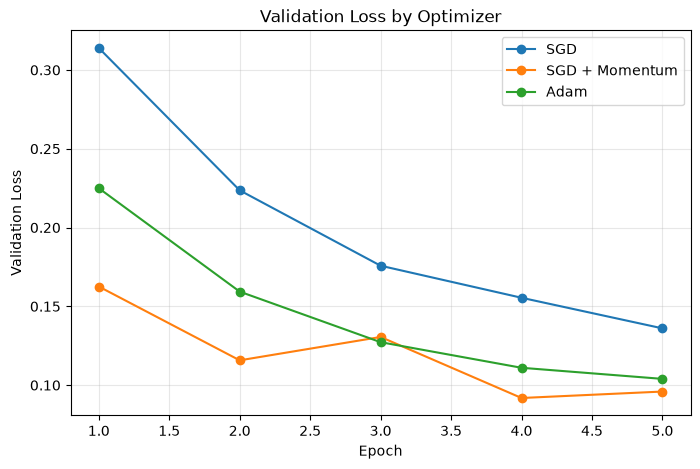

In [9]:
epoch_numbers = range(
    1,
    NUMBER_OF_EPOCHS + 1,
)

plt.figure(figsize=(8, 5))

for optimizer_name, result in (
    experiment_results.items()
):
    plt.plot(
        epoch_numbers,
        result["validation_loss"],
        marker="o",
        label=optimizer_name,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss by Optimizer")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 12. 검증 정확도 비교

짧은 5 Epoch 안에서 검증 정확도가 얼마나 빠르게 높아지는지 확인합니다.

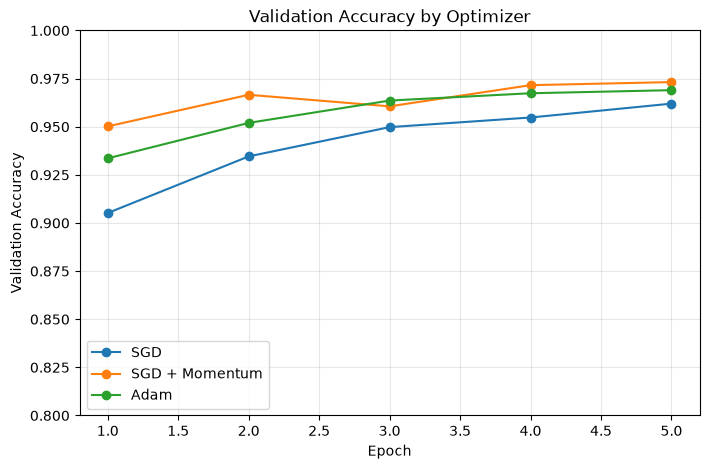

In [10]:
plt.figure(figsize=(8, 5))

for optimizer_name, result in (
    experiment_results.items()
):
    plt.plot(
        epoch_numbers,
        result["validation_accuracy"],
        marker="o",
        label=optimizer_name,
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy by Optimizer")
plt.ylim(0.8, 1.0)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

## 13. 최고 검증 결과 비교

마지막 Epoch가 아니라 각 Optimizer가 기록한 최고 검증 결과를 비교합니다.

In [11]:
print(
    "Optimizer         | Best Epoch | "
    "Best Val Loss | Best Val Accuracy"
)

print("-" * 69)

for optimizer_name, result in (
    experiment_results.items()
):
    print(
        f"{optimizer_name:<17} | "
        f"{result['best_epoch']:>10d} | "
        f"{result['best_validation_loss']:>13.4f} | "
        f"{result['best_validation_accuracy']:>17.4f}"
    )

Optimizer         | Best Epoch | Best Val Loss | Best Val Accuracy
---------------------------------------------------------------------
SGD               |          5 |        0.1360 |            0.9620
SGD + Momentum    |          5 |        0.0959 |            0.9732
Adam              |          5 |        0.1040 |            0.9690


## 14. 검증으로 Optimizer 선택하기

선택 기준:

1. 최고 검증 정확도가 높은 모델
2. 정확도가 같으면 검증 손실이 낮은 모델

테스트 데이터는 아직 사용하지 않습니다.

In [12]:
selected_optimizer_name = max(
    experiment_results,
    key=lambda name: (
        experiment_results[name][
            "best_validation_accuracy"
        ],
        -experiment_results[name][
            "best_validation_loss"
        ],
    ),
)

selected_result = experiment_results[
    selected_optimizer_name
]

selected_model = selected_result[
    "model"
]

print(
    "검증으로 선택한 Optimizer:",
    selected_optimizer_name,
)

print(
    "선택 Epoch:",
    selected_result["best_epoch"],
)

검증으로 선택한 Optimizer: SGD + Momentum
선택 Epoch: 5


## 15. 선택 모델의 테스트 최종 평가

검증으로 Optimizer를 선택한 뒤, 선택된 모델 하나만 테스트 데이터 10,000개로 평가합니다.

In [13]:
test_loss, test_accuracy = evaluate_model(
    selected_model,
    test_loader,
)

print(
    "선택한 Optimizer:",
    selected_optimizer_name,
)

print(
    f"테스트 손실: {test_loss:.4f}"
)

print(
    f"테스트 정확도: {test_accuracy:.4f}"
)

print(
    f"맞힌 이미지 수: "
    f"{int(test_accuracy * len(test_dataset)):,}"
    f" / {len(test_dataset):,}"
)

선택한 Optimizer: SGD + Momentum
테스트 손실: 0.1023
테스트 정확도: 0.9726
맞힌 이미지 수: 9,726 / 10,000


## 16. 테스트 이미지 예측

테스트 이미지 5개에 대해 실제 정답과 예측값을 확인합니다.

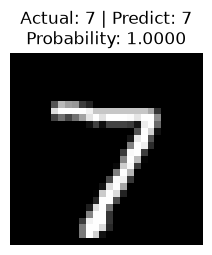

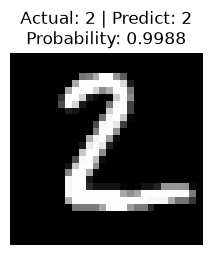

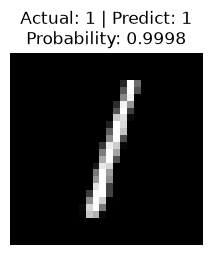

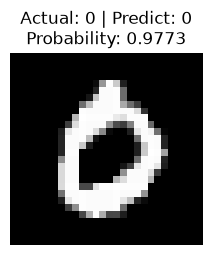

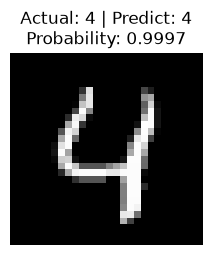

In [14]:
test_images, test_labels = next(
    iter(test_loader)
)

selected_model.eval()

with torch.no_grad():
    test_logits = selected_model(
        test_images.to(device)
    )

    test_probabilities = torch.softmax(
        test_logits,
        dim=1,
    ).cpu()

    test_predictions = test_logits.argmax(
        dim=1
    ).cpu()

for index in range(5):
    actual = test_labels[index].item()
    predicted = test_predictions[index].item()

    confidence = test_probabilities[
        index,
        predicted,
    ].item()

    plt.figure(figsize=(2.5, 2.5))

    plt.imshow(
        test_images[index].squeeze(),
        cmap="gray",
    )

    plt.title(
        f"Actual: {actual} | "
        f"Predict: {predicted}\n"
        f"Probability: {confidence:.4f}"
    )

    plt.axis("off")
    plt.show()

## 17. 결과 해석

일반적으로 짧은 MNIST MLP 실습에서는 다음 경향을 관찰할 수 있습니다.

- SGD: 구조가 단순하지만 초반 학습이 느릴 수 있음
- SGD + Momentum: SGD보다 빠르고 안정적으로 수렴할 수 있음
- Adam: 짧은 Epoch에서도 빠르게 높은 정확도에 도달하는 경우가 많음

그러나 이번 실행에서 Adam이 가장 높게 나오더라도 항상 모든 문제에서 Adam이 가장 좋다는 의미는 아닙니다.

모델 구조·데이터·학습률·Epoch 수가 달라지면 결과도 달라질 수 있습니다.

## 19. 핵심 정리

- Optimizer는 계산된 기울기를 이용해 가중치를 갱신합니다.
- Optimizer별 일반적인 시작 학습률을 사용한 실용적 비교입니다.
- 하나의 실험 결과만으로 특정 Optimizer가 항상 최고라고 결론 내리지 않습니다.